# TP7 — Préparer du texte : NLTK, spaCy et l'effet sur un modèle
**ÉNONCÉ** · Durée estimée : **une demi-journée**

## 🎯 Ce que vous allez apprendre
- Pourquoi un modèle ne sait pas lire du texte brut, et ce que veut dire **pré-traiter**
- Découper en mots, retirer les **mots vides**, ramener les mots à une forme de base : **racine (NLTK)** contre **lemme (spaCy)**
- **Extraire des entités** (personnes, lieux, organisations) et repérer les **ambiguïtés**
- Transformer le texte en nombres (**TF-IDF**) et **mesurer honnêtement** ce que le prétraitement apporte

## 🧰 Boîte à outils
Noms de fonctions et de classes utiles. **Aucun exemple d'appel n'est donné** : cherchez dans la documentation (scikit-learn, Keras, NumPy, matplotlib) comment les utiliser.

`RegexpTokenizer`  ·  `tokenize`  ·  `PorterStemmer`  ·  `stem`  ·  `nlp.Defaults.stop_words`  ·  `token.lemma_`  ·  `token.is_alpha`  ·  `token.is_stop`  ·  `doc.ents`  ·  `ent.label_`  ·  `spacy.explain`  ·  `nlp.pipe`  ·  `TfidfVectorizer`  ·  `LogisticRegression`  ·  `Counter`

## 📘 Comment travailler
- Les cellules **déjà écrites** sont à lire et à exécuter.
- Les cellules **🎯 Étape** sont à **écrire vous-même**, à partir de la consigne.
- Après chaque étape, une cellule **✅ Contrôle** vérifie votre résultat. Respectez les **noms de variables** demandés.
- Les questions **✍️** demandent une réponse écrite : c'est là que vous montrez que vous avez compris.
- Bloqué ? Relisez l'indice, puis cherchez dans la documentation. Un message d'erreur se lit : la dernière ligne dit souvent ce qui ne va pas.

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from nltk.tokenize import RegexpTokenizer
from nltk.stem import PorterStemmer

import spacy
try:
    nlp = spacy.load("en_core_web_sm", disable=["parser"])
except OSError:
    spacy.cli.download("en_core_web_sm")
    nlp = spacy.load("en_core_web_sm", disable=["parser"])

def controle(condition, ok, ko):
    print("✅", ok) if condition else print("❌", ko)

## Étape 1 — Les données : 2 400 lignes, 2 346 résumés de films distincts, horreur ou comédie ?
Un **résumé de film** est du **texte brut** : ce qu'on appelle une donnée **non structurée** (pas de colonnes, pas de nombres). Notre but : deviner si le film est une **horreur (1)** ou une **comédie (0)** à partir de son seul résumé. Le fichier contient 1 200 lignes de chaque sorte, mais **54 résumés y figurent en double** : on les retire à l'étape suivante. Il reste 2 346 textes (1 195 comédies, 1 151 horreurs), donc une classification **presque équilibrée**.

Si vous n'avez pas encore installé les outils : `pip install spacy nltk` puis `python -m spacy download en_core_web_sm`.

In [3]:
path_text = "/home/projects/neural-network/data" #data
df = pd.read_csv(f"{path_text}/textes_films_horreur_comedie.csv")
print(df.shape, "| horreur (1) :", int(df["cible"].sum()), "| comédie (0) :", int((df["cible"] == 0).sum()))
for i in (0, 1, 2):
    print("•", "HORREUR" if df["cible"][i] else "COMÉDIE", "|", df["resume"][i][:220], "...\n")

(2400, 3) | horreur (1) : 1200 | comédie (0) : 1200
• COMÉDIE | Roberto has a new job as the teacher at a nursery school. The first child he meets is Gianluigi, who's mute. Roberto is spirited, bringing a TV into class, then a donkey. He takes children on an unscheduled field trip to ...

• HORREUR | Five years after killing the goalie hockey-masked killer Jason Voorhees, Tommy Jarvis has grown up in various mental hospitals unable to get over the nightmares about Jason's return. When Tommy is sent to a rural halfway ...

• COMÉDIE | Everybody knows that your life is a story. But what if a story was your life? Harold Crick is your average IRS agent: monotonous, boring, and repetitive. But one day this all changes when Harold begins to hear an author  ...



## Étape 1 bis — Vérifier les données avant de les utiliser : les doublons
Le fichier contient des **résumés identiques**. C'est un piège : si le même texte se retrouve dans l'apprentissage **et** dans le test, le modèle le « connaît déjà » et la mesure est **trop optimiste** (c'est une autre forme de **fuite de données**).

**À faire :** comptez les résumés en double, vérifiez qu'un même résumé n'a pas deux cibles différentes, puis gardez **une seule ligne par résumé** (`drop_duplicates`).

In [4]:
n_avant = len(df)
n_doublons = int(df["resume"].duplicated().sum())
contradictoires = int((df.groupby("resume")["cible"].nunique() > 1).sum())

df = df.drop_duplicates(subset="resume").reset_index(drop=True)

print(f"{n_avant} lignes | {n_doublons} résumés en double | {contradictoires} résumé(s) avec deux cibles différentes")
print(f"Après nettoyage : {len(df)} textes | horreur (1) : {int(df['cible'].sum())} | comédie (0) : {int((df['cible'] == 0).sum())}")

2400 lignes | 54 résumés en double | 0 résumé(s) avec deux cibles différentes
Après nettoyage : 2346 textes | horreur (1) : 1151 | comédie (0) : 1195


In [5]:
# ✅ Contrôle (ne pas modifier)
controle(df['resume'].is_unique and contradictoires == 0 and len(df) + n_doublons == n_avant, 'Plus aucun résumé en double : %d textes conservés' % len(df), 'Attendu : un résumé unique par ligne, sans cible contradictoire')

✅ Plus aucun résumé en double : 2346 textes conservés


## 🎯 Étape 2 — Étape 1 du prétraitement : découper en mots (tokenisation)
Un modèle ne lit pas des phrases : il compte des **mots**. La première opération consiste à **découper** le texte en unités, appelées **tokens**. On passe aussi en **minuscules**, pour que « Killer » et « killer » soient le même mot : c'est de la **normalisation**.

**À faire :** Prenez le **premier résumé** de `df` (`texte`). Avec un **`RegexpTokenizer` de NLTK** qui ne garde que les suites de lettres (`[a-zA-Z]+`), découpez-le en mots, **en minuscules**. Stockez la liste dans `mots` et affichez le nombre de mots et les 15 premiers.

> 💡 **Indice** : `RegexpTokenizer(r"[a-zA-Z]+")` puis la méthode `.tokenize(...)`. Pour les minuscules : `.lower()` sur le texte.

In [6]:
texte = df["resume"].iloc[0]
decoupeur = RegexpTokenizer(r"[a-zA-Z]+")
mots = decoupeur.tokenize(texte.lower())
print(len(mots), "mots")
print(mots[:15])

122 mots
['roberto', 'has', 'a', 'new', 'job', 'as', 'the', 'teacher', 'at', 'a', 'nursery', 'school', 'the', 'first', 'child']


In [7]:
# ✅ Contrôle (ne pas modifier)
controle(len(mots) > 20 and all(m == m.lower() for m in mots), 'Texte découpé en %d mots, tous en minuscules' % len(mots), 'Attendu : une liste de mots en minuscules')

✅ Texte découpé en 122 mots, tous en minuscules


Word cloud successfully generated and saved as '/home/projects/neural-network/resources/Eritrea_wordcloud_output.png'!


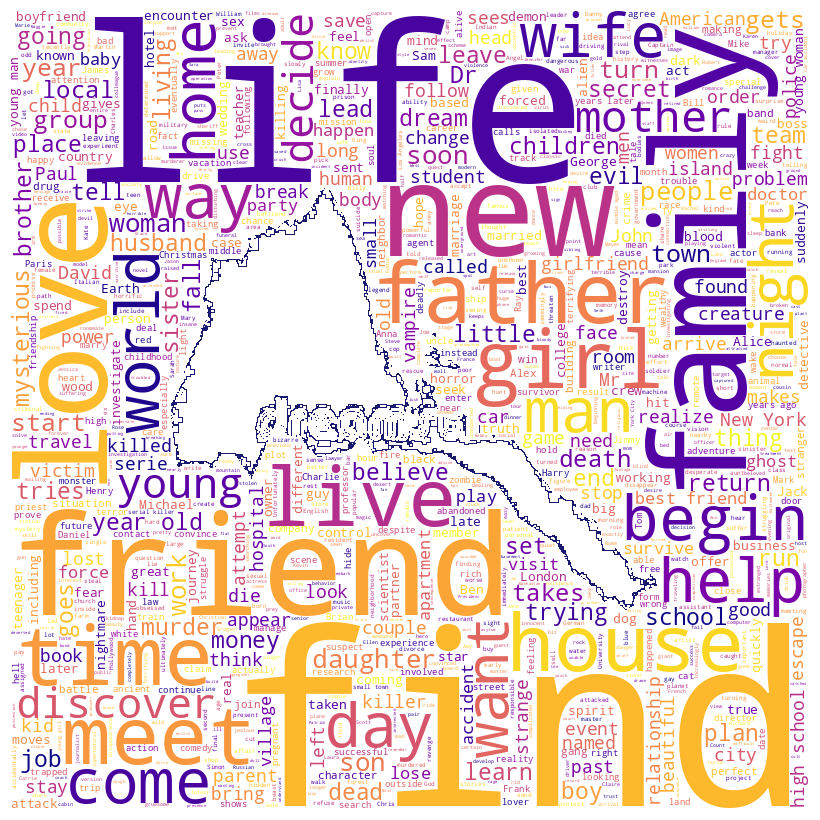

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from wordcloud import WordCloud, STOPWORDS

# 1. Define your source text : Drop any potential NaN (missing) values and convert everything to string
text_data = " ".join(df["resume"].dropna().astype(str))
# 2. Load the Eritrean map mask image
# Make sure 'eritrea_mask.png' is in your directory 
# (The shape should be a dark silhouette on a white background)
mask_filename = "/home/projects/neural-network/resources/eritrea_mask.png"

try:
    eritrea_mask = np.array(Image.open(mask_filename))
except FileNotFoundError:
    print(f"Error: '{mask_filename}' not found. Please download a France silhouette PNG and save it as '{mask_filename}'.")
    exit()

# 3. Set up stopwords (common words to ignore)
stopwords = set(STOPWORDS)
# Combine WordCloud's stop words with spaCy's English stop words
stopwords.update(nlp.Defaults.stop_words)

# Remove frequent words that are not useful for distinguishing film summaries
stopwords.update({"film", "movie", "story"})

# 4. Configure and generate the Word Cloud
wc = WordCloud(
    background_color="white",       # Background color of the output
    max_words=1000,                 # Maximum number of words
    mask=eritrea_mask,               # Apply the Eritrean map shape
    stopwords=stopwords,            # Filter out generic words
    contour_width=1,                # Width of the border outline
    contour_color='midnightblue',   # Color of the border outline
    colormap='plasma'               # Color palette for the words (e.g., 'viridis', 'plasma', 'inferno')
)

# Generate the word cloud from text
wc.generate(text_data)

# 5. Save the output image
output_filename = "/home/projects/neural-network/resources/Eritrea_wordcloud_output.png"
wc.to_file(output_filename)
print(f"Word cloud successfully generated and saved as '{output_filename}'!")

# 6. Display the result using Matplotlib
plt.figure(figsize=(10,8))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")  # Hide the axes
plt.tight_layout(pad=0)
plt.show()

## 🎯 Étape 3 — Étape 2 : retirer les mots vides (stop words)
Dans un texte, beaucoup de mots (« the », « of », « and », « he »…) sont partout, dans les horreurs comme dans les comédies : ils n'aident pas à les distinguer. On les appelle des **mots vides**. Les retirer **réduit le bruit**.

**À faire :** `spaCy` fournit une liste de mots vides anglais : `nlp.Defaults.stop_words`. Stockez-la dans `mots_vides`, puis gardez dans `mots_utiles` uniquement les mots de `mots` qui n'y figurent pas. Affichez le nombre de mots avant et après.

> 💡 **Indice** : Une liste en compréhension : `[m for m in mots if m not in mots_vides]`.

In [9]:
mots_vides = nlp.Defaults.stop_words
mots_utiles = [m for m in mots if m not in mots_vides]
print("Avant :", len(mots), "mots | après :", len(mots_utiles), "mots")

Avant : 122 mots | après : 63 mots


In [10]:
# ✅ Contrôle (ne pas modifier)
controle(len(mots_utiles) < len(mots) and 'the' not in mots_utiles, 'Mots vides retirés : %d -> %d mots' % (len(mots), len(mots_utiles)), 'Attendu : moins de mots qu\'avant, et plus de « the »')

✅ Mots vides retirés : 122 -> 63 mots


## 🎯 Étape 4 — Étape 3 : ramener les mots à une racine avec NLTK (stemming)
« kill », « killed », « killer » parlent de la même chose. Le **stemming** coupe mécaniquement les fins de mots pour obtenir une **racine** (qui n'est pas toujours un vrai mot). C'est rapide, mais « bête » : il ne connaît pas la grammaire.

**À faire :** Avec le **`PorterStemmer` de NLTK**, calculez la racine de chaque mot de la phrase ci-dessous. Stockez la liste dans `racines` et affichez les couples (mot, racine).

> 💡 **Indice** : `PorterStemmer()` puis `.stem(mot)`.

In [11]:
phrase = "The killers ran away while he was studying better methods"
mots_phrase = phrase.lower().split()
racineur = PorterStemmer()
racines = [racineur.stem(m) for m in mots_phrase]
for m, r in zip(mots_phrase, racines):
    print(f"{m:<10} → {r}")

the        → the
killers    → killer
ran        → ran
away       → away
while      → while
he         → he
was        → wa
studying   → studi
better     → better
methods    → method


In [12]:
# ✅ Contrôle (ne pas modifier)
controle(racines[mots_phrase.index('studying')] == 'studi' and racines[mots_phrase.index('ran')] == 'ran', 'Racines calculées (remarquez « studi » et « ran »)', 'Attendu : studying -> studi, et ran reste ran')

✅ Racines calculées (remarquez « studi » et « ran »)


### ✍️ Question
**Regardez « studying → studi » et « ran → ran ». Qu'est-ce que le stemming sait faire, et qu'est-ce qu'il ne sait pas faire ?**

*Votre réponse (2 à 4 lignes) :*
> Le stemming sait couper mécaniquement la fin des mots (comme `-ing` ou `-s`) pour regrouper des formes proches, et il est rapide. Mais il ne connaît pas la grammaire : « studying » devient « studi », qui n'est pas un vrai mot, et « ran » reste « ran » alors que c'est une forme de « run ».

## 🎯 Étape 5 — Étape 4 : ramener les mots à leur forme de base avec spaCy (lemmatisation)
La **lemmatisation** fait la même chose en **comprenant la grammaire** : le **lemme** est le mot du dictionnaire (« ran » → « run », « was » → « be »). C'est plus lent mais plus juste.

**À faire :** Passez la même `phrase` dans spaCy (`doc = nlp(phrase)`). Construisez un tableau pandas **`tableau`** de 10 lignes avec 3 colonnes : `mot`, `racine NLTK` (réutilisez `racines`) et `lemme spaCy`. Affichez-le.

> 💡 **Indice** : Pour chaque `token` de `doc` : `token.text` et `token.lemma_`.

In [13]:
doc = nlp(phrase)
tableau = pd.DataFrame({
    "mot": mots_phrase,
    "racine NLTK": racines,
    "lemme spaCy": [token.lemma_ for token in doc],
})
tableau

,mot,racine NLTK,lemme spaCy
0,the,the,the
1,killers,killer,killer
2,ran,ran,run
3,away,away,away
4,while,while,while
5,he,he,he
6,was,wa,be
7,studying,studi,study
8,better,better,well
9,methods,method,method


In [14]:
# ✅ Contrôle (ne pas modifier)
controle(tableau.shape == (10, 3) and tableau.loc[tableau['mot'] == 'ran', 'lemme spaCy'].iloc[0] == 'run' and tableau.loc[tableau['mot'] == 'was', 'lemme spaCy'].iloc[0] == 'be', 'Tableau correct : ran -> run, was -> be', 'Attendu 10 lignes, avec ran -> run et was -> be')

✅ Tableau correct : ran -> run, was -> be


### ✍️ Question
**Comparez les colonnes « racine NLTK » et « lemme spaCy ». Dans quel cas préféreriez-vous l'une ou l'autre ?**

*Votre réponse (2 à 4 lignes) :*
> La racine NLTK est une forme coupée, parfois fausse (« studi »), alors que le lemme spaCy est un vrai mot du dictionnaire (« study », « ran » → « run », « was » → « be »). Je préfère la racine pour aller vite sur beaucoup de texte quand la lisibilité n'importe pas, et le lemme quand la justesse grammaticale compte ou que je veux relire les mots obtenus.

## 🎯 Étape 6 — Étape 5 : extraire les entités nommées
Une **entité nommée** est un nom propre de personne, de lieu, d'organisation, une date, un nombre… spaCy les repère automatiquement. Extraire les entités permet de savoir **de qui, d'où, de quand** parle un texte, et de créer des variables utiles.

**À faire :** 1) Passez le **premier résumé** dans spaCy et affichez ses entités (texte → type, avec la signification du type). 2) Passez les **300 premiers résumés** dans `nlp.pipe(...)` et comptez les **types d'entités** dans `types` (un `Counter`).

> 💡 **Indice** : `for ent in doc.ents:` donne `ent.text` et `ent.label_`. `spacy.explain("GPE")` donne la signification. `nlp.pipe(liste_de_textes, batch_size=64)` traite beaucoup de textes plus vite qu'un par un.

In [15]:
# 1) Entités du premier résumé
doc1 = nlp(df["resume"].iloc[0])
for ent in doc1.ents:
    print(f"{ent.text} → {ent.label_} ({spacy.explain(ent.label_)})")

# 2) Types d'entités dans les 300 premiers résumés
docs300 = list(nlp.pipe(df["resume"].iloc[:300], batch_size=64))
types = Counter(ent.label_ for d in docs300 for ent in d.ents)
print()
print(types.most_common())

Roberto → PERSON (People, including fictional)
first → ORDINAL ("first", "second", etc.)
Gianluigi → PERSON (People, including fictional)
Roberto → PERSON (People, including fictional)
Isabella → PERSON (People, including fictional)
one → CARDINAL (Numerals that do not fall under another type)
Isabella → PERSON (People, including fictional)
Sardinia → GPE (Countries, cities, states)
Roberto → PERSON (People, including fictional)
ten → CARDINAL (Numerals that do not fall under another type)
Gianluigi → PERSON (People, including fictional)
Sardinia → GPE (Countries, cities, states)
Gianluigi → PERSON (People, including fictional)

[('PERSON', 1067), ('ORG', 275), ('GPE', 227), ('DATE', 178), ('CARDINAL', 152), ('NORP', 76), ('ORDINAL', 36), ('TIME', 32), ('WORK_OF_ART', 31), ('LOC', 23), ('PRODUCT', 18), ('FAC', 8), ('MONEY', 7), ('QUANTITY', 3), ('EVENT', 3), ('LAW', 1), ('LANGUAGE', 1)]


In [16]:
# ✅ Contrôle (ne pas modifier)
controle('PERSON' in types and sum(types.values()) > 300, 'Entités extraites : %d dans 300 résumés' % sum(types.values()), 'Attendu des entités de type PERSON et plus de 300 au total')

✅ Entités extraites : 2138 dans 300 résumés


## 🎯 Étape 7 — Étape 6 : chasser les ambiguïtés
Une extraction automatique n'est **pas parfaite** : un même nom peut recevoir **plusieurs étiquettes** selon le contexte (un prénom pris pour une organisation, un lieu pour une personne…). Le référentiel parle de **réduction des ambiguïtés** : il faut d'abord **les repérer**.

**À faire :** À partir de `docs300`, construisez le dictionnaire `etiquettes` (clé = texte de l'entité, valeur = **ensemble** des types qu'elle a reçus), puis `ambigus` : celles qui ont **au moins 2 types différents**. Affichez le nombre d'entités ambiguës et **10 exemples**.

> 💡 **Indice** : `etiquettes.setdefault(ent.text, set()).add(ent.label_)`.

In [17]:
etiquettes = {}
for d in docs300:
    for ent in d.ents:
        etiquettes.setdefault(ent.text, set()).add(ent.label_)

ambigus = {texte_ent: tp for texte_ent, tp in etiquettes.items() if len(tp) >= 2}
print(len(ambigus), "entités ambiguës sur", len(etiquettes), "entités différentes")
for texte_ent, tp in list(ambigus.items())[:10]:
    print(f"  {texte_ent} → {sorted(tp)}")

34 entités ambiguës sur 1318 entités différentes
  Pierre → ['ORG', 'PERSON']
  Julia → ['GPE', 'ORG']
  Channard → ['ORG', 'PERSON']
  Cronos → ['ORG', 'PERSON']
  Mercedes → ['ORG', 'PERSON']
  Alice → ['ORG', 'PERSON']
  Steven → ['ORG', 'PERSON']
  Tillie → ['GPE', 'PERSON']
  Sunny → ['ORG', 'PERSON']
  Ace Ventura → ['GPE', 'PERSON']


In [18]:
# ✅ Contrôle (ne pas modifier)
controle(len(ambigus) > 0, '%d entités ambiguës repérées' % len(ambigus), 'Attendu au moins une entité avec plusieurs types')

✅ 34 entités ambiguës repérées


### ✍️ Question
**Quelles ambiguïtés avez-vous trouvées ? Que feriez-vous pour fiabiliser ces extractions avant d'entraîner un modèle ?**

*Votre réponse (2 à 4 lignes) :*
> *Réponse rédigée avec vos résultats dans la cellule de code ci-dessous (exécutez-la).*

In [19]:
# ✍️ Réponse rédigée à partir de vos résultats
from IPython.display import Markdown, display

exemples = "; ".join(f"« {t} » ({' / '.join(sorted(tp))})" for t, tp in list(ambigus.items())[:3])
display(Markdown(
    f"> {len(ambigus)} entités reçoivent plusieurs types, par exemple {exemples} : le même nom est pris tantôt pour une personne, un lieu ou une organisation selon le contexte. "
    "Pour fiabiliser, je vérifierais à la main un échantillon, je fixerais un seul type par nom (par exemple le plus fréquent) ou j'ajouterais des règles ou des listes de référence, avant d'entraîner un modèle."
))

> 34 entités reçoivent plusieurs types, par exemple « Pierre » (ORG / PERSON); « Julia » (GPE / ORG); « Channard » (ORG / PERSON) : le même nom est pris tantôt pour une personne, un lieu ou une organisation selon le contexte. Pour fiabiliser, je vérifierais à la main un échantillon, je fixerais un seul type par nom (par exemple le plus fréquent) ou j'ajouterais des règles ou des listes de référence, avant d'entraîner un modèle.

## 🎯 Étape 8 — Étape 7 : le pipeline complet
On assemble tout : un texte brut entre, un **texte propre** sort, en minuscules, **sans ponctuation, sans mots vides, avec des lemmes**.

**À faire :** Écrivez `nettoyer_doc(doc)` qui reçoit un document spaCy et renvoie une chaîne : les **lemmes en minuscules** des tokens qui sont **alphabétiques** (`is_alpha`) et **pas des mots vides** (`is_stop`), séparés par des espaces. Appliquez-la à **tous** les résumés dans une colonne `df["propre"]` (⏱️ environ 20 secondes).

> 💡 **Indice** : `nlp.pipe(df["resume"], batch_size=128)` donne les documents un par un. Les attributs : `token.lemma_`, `token.is_alpha`, `token.is_stop`.

In [20]:
def nettoyer_doc(doc):
    return " ".join(t.lemma_.lower() for t in doc if t.is_alpha and not t.is_stop)

df["propre"] = [nettoyer_doc(d) for d in nlp.pipe(df["resume"], batch_size=128)]
print(df["propre"].iloc[0][:200])

roberto new job teacher nursery school child meet gianluigi mute roberto spirited bring tv class donkey take child unscheduled field trip father plant date isabella mother student soon pregnant moody 


In [21]:
# ✅ Contrôle (ne pas modifier)
controle('propre' in df.columns and df['propre'].notna().all() and ',' not in df['propre'].iloc[0] and df['propre'].str.len().min() > 0, 'Colonne propre créée pour les %d textes' % len(df), 'Vérifiez nettoyer_doc : pas de ponctuation, aucun texte vide')

✅ Colonne propre créée pour les 2346 textes


## Étape 9 — Deux autres versions du texte, pour comparer
On prépare aussi une version « **minuscules** » et une version « **racines NLTK** » (avec les outils des étapes 1 à 3), pour comparer les traitements à l'étape 9.

In [22]:
def racines_texte(texte):
    return " ".join(racineur.stem(m) for m in decoupeur.tokenize(texte.lower()) if m not in mots_vides)

df["minuscules"] = df["resume"].str.lower()
df["racines"] = df["resume"].apply(racines_texte)
print(df[["resume", "minuscules", "racines", "propre"]].iloc[0].apply(lambda s: s[:90]).to_string())

resume        Roberto has a new job as the teacher at a nurs...
minuscules    roberto has a new job as the teacher at a nurs...
racines       roberto new job teacher nurseri school child m...
propre        roberto new job teacher nursery school child m...


## 🎯 Étape 10 — Étape 8 : transformer le texte en nombres, et entraîner
Pour qu'un modèle lise un texte, on le transforme en **nombres** : le **TF-IDF** donne à chaque mot un poids élevé s'il est **fréquent dans ce texte** et **rare dans les autres** (« killer » aide ; « the » n'aide pas). Le **vocabulaire** (la liste des mots connus) **s'apprend sur l'apprentissage seul**, sinon le test « souffle » des informations : c'est une **fuite de données**.

**À faire :** 1) Découpez `df` en `train` / `test` : **25 % de test**, **stratifié sur `cible`**, `random_state=42`. 2) Pour chaque colonne **`resume`** (texte brut) et **`propre`** (texte nettoyé) : apprenez un `TfidfVectorizer` **sur `train` seulement**, entraînez une `LogisticRegression(max_iter=2000)`, puis calculez sur `test` la **précision**, le **F1** et la **taille du vocabulaire**. Rangez dans un dictionnaire `resultats` (clés `"resume"` et `"propre"`) et affichez-le en tableau.

> 💡 **Indice** : `vec.fit_transform(train[col])` sur l'apprentissage, `vec.transform(test[col])` sur le test. `X.shape[1]` = nombre de mots du vocabulaire.

In [23]:
train, test = train_test_split(df, test_size=0.25, stratify=df["cible"], random_state=42)

resultats = {}
for col in ("resume", "propre"):
    vec = TfidfVectorizer()
    X_tr = vec.fit_transform(train[col])      # vocabulaire appris sur le train seul
    X_te = vec.transform(test[col])
    modele = LogisticRegression(max_iter=2000).fit(X_tr, train["cible"])
    pred = modele.predict(X_te)
    resultats[col] = {
        "précision": float(np.mean(pred == test["cible"])),
        "F1": float(f1_score(test["cible"], pred)),
        "mots du vocabulaire": X_tr.shape[1],
    }

pd.DataFrame(resultats).T

,précision,F1,mots du vocabulaire
resume,0.841567,0.839931,16810.0
propre,0.882453,0.876565,13366.0


In [24]:
# ✅ Contrôle (ne pas modifier)
controle(len(train) + len(test) == len(df) and abs(len(test) / len(df) - 0.25) < 0.01 and 0.7 < resultats['resume']['précision'] < 0.95 and resultats['propre']['mots du vocabulaire'] < resultats['resume']['mots du vocabulaire'], 'Comparaison faite : vocabulaire réduit à %d mots' % resultats['propre']['mots du vocabulaire'], 'Attendu : 75 % des textes en apprentissage, précisions entre 0.7 et 0.95, vocabulaire réduit après nettoyage')

✅ Comparaison faite : vocabulaire réduit à 13366 mots


## Étape 11 — Étape 9 : le prétraitement améliore-t-il vraiment ? Mesurons sur 5 découpages
Un seul découpage ne prouve rien : le hasard du découpage fait varier le résultat. On **répète 5 fois** avec des découpages différents et on regarde la **moyenne** et l'**écart-type** (± : la dispersion). On le fait aussi avec **200 textes seulement**, pour voir ce qui change quand les données sont rares.

⏱️ Quelques dizaines de secondes.

In [25]:
def evaluer(colonne, taille=None, **options):
    scores, voc = [], []
    for graine in range(5):
        tr, te = train_test_split(df, test_size=0.25, stratify=df["cible"], random_state=graine)
        if taille:
            tr = tr.sample(taille, random_state=graine)
        vec = TfidfVectorizer(**options); X = vec.fit_transform(tr[colonne])
        m = LogisticRegression(max_iter=2000).fit(X, tr["cible"])
        scores.append(np.mean(m.predict(vec.transform(te[colonne])) == te["cible"])); voc.append(X.shape[1])
    return np.mean(scores), np.std(scores), int(np.mean(voc))

configs = [("texte brut (sans minuscules)", "resume", dict(lowercase=False)), ("minuscules", "minuscules", {}),
           ("minuscules + mots vides retirés", "minuscules", dict(stop_words="english")),
           ("racines NLTK + mots vides retirés", "racines", {}), ("lemmes spaCy + mots vides retirés", "propre", {})]
lignes = []
for nom, col, opt in configs:
    m1, s1, v1 = evaluer(col, **opt); m2, s2, _ = evaluer(col, taille=200, **opt)
    lignes.append({"traitement": nom, "précision (apprentissage complet)": f"{m1:.3f} ± {s1:.3f}", "précision (200 textes)": f"{m2:.3f} ± {s2:.3f}", "mots du vocabulaire": v1})
bilan = pd.DataFrame(lignes)
bilan

,traitement,précision (apprentissage complet),précision (200 textes),mots du vocabulaire
0,texte brut (sans minuscules),0.841 ± 0.005,0.678 ± 0.049,18710
1,minuscules,0.836 ± 0.011,0.680 ± 0.047,17030
2,minuscules + mots vides retirés,0.872 ± 0.009,0.664 ± 0.069,16745
3,racines NLTK + mots vides retirés,0.871 ± 0.011,0.703 ± 0.061,11905
4,lemmes spaCy + mots vides retirés,0.866 ± 0.010,0.697 ± 0.063,13543


### ✍️ Question
**Quelle étape de prétraitement améliore le plus la précision ? Les racines et les lemmes apportent-ils autre chose ? Que se passe-t-il avec 200 textes seulement ?**

*Réponse:*
> *Réponse rédigée avec vos résultats dans la cellule de code ci-dessous (exécutez-la).*

In [26]:
# ✍️ Réponse rédigée à partir de vos résultats
from IPython.display import Markdown, display

m = bilan["précision (apprentissage complet)"].str.split(" ± ").str[0].astype(float).tolist()
p = bilan["précision (200 textes)"].str.split(" ± ").str[0].astype(float).tolist()
s1 = bilan["précision (apprentissage complet)"].str.split(" ± ").str[1].astype(float).tolist()
s2 = bilan["précision (200 textes)"].str.split(" ± ").str[1].astype(float).tolist()
voc = bilan["mots du vocabulaire"].tolist()

gains = {"passer en minuscules": m[1] - m[0], "retirer les mots vides": m[2] - m[1],
         "les racines NLTK": m[3] - m[2], "les lemmes spaCy": m[4] - m[2]}
meilleur = max(gains, key=gains.get)
verbe = "réduisent" if max(voc[3], voc[4]) < voc[2] else "modifient"
display(Markdown(
    f"> L'étape qui change le plus la précision est « {meilleur} » ({gains[meilleur]:+.3f}). "
    f"Les racines et les lemmes changent la précision de {gains['les racines NLTK']:+.3f} et {gains['les lemmes spaCy']:+.3f}, mais ils {verbe} le vocabulaire (de {voc[2]} à {voc[3]} et {voc[4]} mots). "
    f"Avec 200 textes, la précision est de {p[2]:.3f} au lieu de {m[2]:.3f} et l'écart-type passe de {s1[2]:.3f} à {s2[2]:.3f} : le hasard masque les petites différences."
))

> L'étape qui change le plus la précision est « retirer les mots vides » (+0.036). Les racines et les lemmes changent la précision de -0.001 et -0.006, mais ils réduisent le vocabulaire (de 16745 à 11905 et 13543 mots). Avec 200 textes, la précision est de 0.664 au lieu de 0.872 et l'écart-type passe de 0.009 à 0.069 : le hasard masque les petites différences.

## ✅ Ce qu'il faut retenir
- Un modèle ne lit pas du texte : on **découpe** (tokens), on **normalise** (minuscules), on **retire les mots vides**, on ramène les mots à une **forme de base** (racine NLTK ou lemme spaCy), puis on **vectorise** (TF-IDF).
- **Racine** (rapide, approximative, « studi ») contre **lemme** (grammaticalement juste, « study », plus lent).
- Les **entités nommées** donnent le « qui, où, quand », mais l'extraction est **imparfaite** : il faut **chercher les ambiguïtés**.
- Le **vocabulaire** s'apprend **sur l'apprentissage seul**.
- **Regarder les données avant de modéliser** : des résumés en double, présents à la fois dans l'apprentissage et le test, rendent la mesure trop optimiste.
- **Mesurer** : un prétraitement améliore parfois nettement (mots vides), parfois seulement la taille du modèle (racines, lemmes), et avec peu de données le hasard masque tout.

## 🧭 Lien avec le référentiel (compétence C.14.3)
| Ce que demande le référentiel | Où dans ce TP |
|---|---|
| Outils NLP comme **SpaCy et NLTK** | NLTK : étapes 1 et 3 · spaCy : étapes 2, 4, 5, 6, 7 |
| **Extraction précise des entités** | Étapes 5 et 6 |
| **Normalisation du texte** | Étapes 1 à 4 et 7 |
| **Réduction des ambiguïtés** | Étape 6 (repérage), étape 3 à 4 (formes d'un même mot) |
| **Optimiser les performances** des modèles | Étapes 8 et 9 |